In [1]:
import json
from pathlib import Path
import cv2
import numpy as np

# ----------------------------- Constants -----------------------------
BASE_DIRECTORY = Path("E:/Aidin/Universities/Amirkabir (Master)/Lessons/My-Terms/Term 4/3D Computer Vision/Assignments/HW1/Answer")
IMAGE_PATH = BASE_DIRECTORY / "Images2" / "3.jpg"
ANNOTATION_STAGE1_JSON = BASE_DIRECTORY / "annotations_stage1.json"
STAGE2_JSON = BASE_DIRECTORY / "stage2_result.json"
OUTPUT_PREFIX = BASE_DIRECTORY / "stage3to5"

# ----------------------------- Helper Functions -----------------------------
def convert_to_homogeneous(point: tuple) -> np.ndarray:
    return np.array([float(point[0]), float(point[1]), 1.0], dtype=np.float64)

def create_line_from_points(point1, point2) -> np.ndarray:
    return np.cross(convert_to_homogeneous(point1), convert_to_homogeneous(point2)).astype(np.float64)

def normalize_line(line: np.ndarray) -> np.ndarray:
    a, b, c = line
    norm = np.hypot(a, b) + 1e-12
    return np.array([a/norm, b/norm, c/norm], dtype=np.float64)

def vanishing_point_least_squares(lines) -> np.ndarray | None:
    if len(lines) < 2: 
        return None
    normalized_lines = np.asarray([normalize_line(create_line_from_points(p1, p2)) for p1, p2 in lines], dtype=np.float64)
    A, c = normalized_lines[:, :2], normalized_lines[:, 2:3]
    vp, *_ = np.linalg.lstsq(A, -c, rcond=None)
    return vp.flatten()

def vanishing_point_ransac(lines, iterations=1000, inlier_threshold=2.5, seed=None):
    if len(lines) < 2: 
        return None, []
    rng = np.random.default_rng(seed)
    normalized_lines = [normalize_line(create_line_from_points(p1, p2)) for p1, p2 in lines]
    n = len(normalized_lines)
    best_vp, best_inliers = None, []
    for _ in range(iterations):
        i, j = rng.choice(n, size=2, replace=False)
        vp_h = np.cross(normalized_lines[i], normalized_lines[j])
        if abs(vp_h[2]) < 1e-9: 
            continue
        vp = vp_h[:2] / vp_h[2]
        distances = np.abs(np.dot(normalized_lines, np.r_[vp, 1.0]))
        inliers = np.where(distances < inlier_threshold)[0].tolist()
        if len(inliers) > len(best_inliers):
            best_inliers, best_vp = inliers, vp
    if best_vp is not None and len(best_inliers) >= 2:
        A = np.array([normalized_lines[i][:2] for i in best_inliers], dtype=np.float64)
        c = np.array([[normalized_lines[i][2]] for i in best_inliers], dtype=np.float64)
        vp_ref, *_ = np.linalg.lstsq(A, -c, rcond=None)
        return vp_ref.flatten(), best_inliers
    return best_vp, best_inliers

def compute_horizon(vx, vy) -> np.ndarray:
    return np.cross(np.r_[vx, 1.0], np.r_[vy, 1.0])

def clip_line_to_image(line, width, height):
    a, b, c = line
    points = []
    if abs(b) > 1e-12: points += [(0.0, -c/b), (width-1.0, -(a*(width-1)+c)/b)]
    if abs(a) > 1e-12: points += [(-c/a, 0.0), (-(b*(height-1)+c)/a, height-1.0)]
    points = [(x, y) for x, y in points if -1 <= x <= width and -1 <= y <= height]
    if len(points) < 2: 
        return None
    best, best_dist = (points[0], points[1]), -1
    for i in range(len(points)):
        for j in range(i+1, len(points)):
            dist = (points[i][0]-points[j][0])**2 + (points[i][1]-points[j][1])**2
            if dist > best_dist: 
                best_dist, best = dist, (points[i], points[j])
    return (int(round(best[0][0])), int(round(best[0][1]))), (int(round(best[1][0])), int(round(best[1][1])))

def order_quad_points(points):
    points = np.asarray(points, dtype=np.float64)
    center = points.mean(axis=0)
    angles = np.arctan2(points[:, 1] - center[1], points[:, 0] - center[0])
    sorted_indices = np.argsort(angles)
    points = points[sorted_indices]
    sum_points = points.sum(axis=1)
    tl_index = int(np.argmin(sum_points))
    return np.roll(points, -tl_index, axis=0)

clip_line_to_image = clip_line_to_image

def project_3d_points(K, R, t, world_points):
    world_points = np.asarray(world_points, dtype=np.float64).T
    camera_points = R @ world_points + t.reshape(3, 1)
    projected_points = K @ camera_points
    projected_points = (projected_points[:2] / projected_points[2]).T
    return projected_points, camera_points.T

def draw_lines_on_image(image, lines, color, thickness=1):
    height, width = image.shape[:2]
    for p1, p2 in lines:
        line = normalize_line(create_line_from_points(p1, p2))
        segment = clip_line_to_image(line, width, height)
        if segment: 
            cv2.line(image, segment[0], segment[1], color, thickness, cv2.LINE_AA)

def draw_vanishing_point(image, vp, label, color=(0, 0, 255)):
    if vp is None: 
        return
    x, y = int(round(vp[0])), int(round(vp[1]))
    cv2.circle(image, (x, y), 6, color, -1, cv2.LINE_AA)
    cv2.putText(image, label, (x+8, y-8), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2, cv2.LINE_AA)

def draw_horizon_on_image(image, v1, v2, color=(0, 0, 255)):
    if v1 is None or v2 is None: 
        return
    line = compute_horizon(v1, v2)
    segment = clip_line_to_image(line, image.shape[1], image.shape[0])
    if segment: 
        cv2.line(image, segment[0], segment[1], color, 1, cv2.LINE_AA)

# ----------------------------- Annotator Class -----------------------------
class Annotator:
    def __init__(self, img, output_prefix: Path | str = BASE_DIRECTORY / "annotations_stage1"):
        self.base_image = img.copy()
        self.display_image = img.copy()
        self.height, self.width = img.shape[:2]
        self.mode = 'quad'
        self.current_group = 'u'
        self.pending_point = None
        self.quad_points = []
        self.quad_ordered = None
        self.line_groups = {'u': [], 'v': []}
        self.vanishing_points = {}
        self.show_preview = False
        self.output_prefix = Path(output_prefix)
        self.is_dirty = True

    def compute_vanishing_points(self):
        vanishing_points = {}
        for group in ('u', 'v'):
            if len(self.line_groups[group]) >= 2:
                try: 
                    vanishing_points[group] = vanishing_point_least_squares(self.line_groups[group])
                except: 
                    pass
        self.vanishing_points = vanishing_points
        return vanishing_points

    def handle_click(self, event, x, y, flags, param):
        if event != cv2.EVENT_LBUTTONDOWN: 
            return
        if self.mode == 'quad':
            if len(self.quad_points) < 4:
                self.quad_points.append((float(x), float(y)))
                if len(self.quad_points) == 4:
                    self.quad_ordered = order_quad_points(self.quad_points)
        elif self.mode == 'lines':
            if self.pending_point is None:
                self.pending_point = (float(x), float(y))
            else:
                p1, p2 = self.pending_point, (float(x), float(y))
                self.line_groups[self.current_group].append((p1, p2))
                self.pending_point = None
        self.is_dirty = True

    def handle_key(self, key):
        if key == ord('q'): 
            self.mode = 'quad'
        elif key == ord('1'): 
            self.mode = 'lines'; self.current_group = 'u'
        elif key == ord('2'): 
            self.mode = 'lines'; self.current_group = 'v'
        elif key == ord('u'): 
            self.undo()
        elif key == ord('x'): 
            self.clear_current()
        elif key == ord('c'): 
            self.clear_all()
        elif key == ord('h'): 
            self.show_preview = not self.show_preview; self.compute_vanishing_points() if self.show_preview else None
        elif key == ord('p'): 
            self.print_state()
        elif key == ord('s'): 
            self.save_all()
        self.is_dirty = True

    def undo(self):
        if self.mode == 'quad':
            if self.quad_points: 
                self.quad_points.pop(); self.quad_ordered = None
        else:
            if self.pending_point: 
                self.pending_point = None
            elif self.line_groups[self.current_group]: 
                self.line_groups[self.current_group].pop()

    def clear_current(self):
        if self.mode == 'quad':
            self.quad_points = []; self.quad_ordered = None
        else:
            self.pending_point = None; self.line_groups[self.current_group] = []

    def clear_all(self):
        self.quad_points = []; self.quad_ordered = None
        self.pending_point = None; self.line_groups = {'u': [], 'v': []}
        self.vanishing_points = {}; self.show_preview = False

    def redraw(self):
        self.display_image = self.base_image.copy()
        for i, (x, y) in enumerate(self.quad_points):
            cv2.circle(self.display_image, (int(x), int(y)), 6, (0, 0, 255), -1)
            cv2.putText(self.display_image, f"{i+1}", (int(x)+6, int(y)-6), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1, cv2.LINE_AA)
        if self.quad_ordered is not None:
            pts = self.quad_ordered.astype(np.int32).reshape(-1, 1, 2)
            cv2.polylines(self.display_image, [pts], True, (255, 0, 255), 2, cv2.LINE_AA)
            for (x, y), label in zip(self.quad_ordered, ["TL", "TR", "BR", "BL"]):
                cv2.circle(self.display_image, (int(x), int(y)), 6, (255, 0, 255), 1)
                cv2.putText(self.display_image, label, (int(x)+6, int(y)-6), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 0, 255), 2, cv2.LINE_AA)
        colors = {'u': (255, 105, 180), 'v': (0, 255, 255)}
        for group in ('u', 'v'):
            for p1, p2 in self.line_groups[group]:
                cv2.circle(self.display_image, (int(p1[0]), int(p1[1])), 5, colors[group], -1)
                cv2.circle(self.display_image, (int(p2[0]), int(p2[1])), 5, colors[group], -1)
                cv2.line(self.display_image, (int(p1[0]), int(p1[1])), (int(p2[0]), int(p2[1])), (255, 0, 0), 2, cv2.LINE_AA)
        if self.pending_point:
            cv2.circle(self.display_image, (int(self.pending_point[0]), int(self.pending_point[1])), 6, (255, 255, 0), -1)
        if self.show_preview:
            if not self.vanishing_points: 
                self.compute_vanishing_points()
            for group, vp in self.vanishing_points.items():
                if vp is None: 
                    continue
                vx, vy = int(round(vp[0])), int(round(vp[1]))
                if -10000 <= vx <= self.width + 10000 and -10000 <= vy <= self.height + 10000:
                    cv2.circle(self.display_image, (vx, vy), 6, (0, 0, 255), -1)
                    cv2.putText(self.display_image, f"VP_{group}", (vx+8, vy-8), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2, cv2.LINE_AA)
            if set(self.vanishing_points.keys()) == {'u', 'v'}:
                horizon_line = compute_horizon(self.vanishing_points['u'], self.vanishing_points['v'])
                segment = clip_line_to_image(horizon_line, self.width, self.height)
                if segment: 
                    cv2.line(self.display_image, segment[0], segment[1], (0, 0, 255), 1, cv2.LINE_AA)
        self.is_dirty = False

    def save_all(self):
        self.compute_vanishing_points()
        overlay_path = self.output_prefix.parent / f"{self.output_prefix.stem}_overlay.png"
        json_path = self.output_prefix
        cv2.imwrite(str(overlay_path), self.display_image)
        data = {
            "image_size": {"width": int(self.width), "height": int(self.height)},
            "quad_raw": np.asarray(self.quad_points, dtype=float).tolist(),
            "quad_ordered": None if self.quad_ordered is None else self.quad_ordered.astype(float).tolist(),
            "lines_u": [[list(map(float, p1)), list(map(float, p2))] for p1, p2 in self.line_groups['u']],
            "lines_v": [[list(map(float, p1)), list(map(float, p2))] for p1, p2 in self.line_groups['v']],
            "vps_preview": {k: [float(v[0]), float(v[1])] for k, v in self.vanishing_points.items()},
        }
        with open(json_path, "w", encoding="utf-8") as file:
            json.dump(data, file, ensure_ascii=False, indent=2)
        print("Saved:", overlay_path, "and", json_path)

# ----------------------------- Running the Annotator -----------------------------
img = cv2.imread(str(IMAGE_PATH))
if img is None: 
    raise FileNotFoundError(f"Image not found: {IMAGE_PATH}")
annotator = Annotator(img, output_prefix=Path(ANNOTATION_STAGE1_JSON))
window_name = "Annotation - Stage 1"
cv2.namedWindow(window_name, cv2.WINDOW_AUTOSIZE)
cv2.setMouseCallback(window_name, lambda e, x, y, f, p: annotator.handle_click(e, x, y, f, p))
while True:
    if annotator.is_dirty: 
        annotator.redraw()
    cv2.imshow(window_name, annotator.display_image)
    key = cv2.waitKey(20) & 0xFF
    if key == 27: 
        annotator.save_all(); 
        break
    elif key != 255: 
        annotator.handle_key(key)
cv2.destroyAllWindows()


Saved: E:\Aidin\Universities\Amirkabir (Master)\Lessons\My-Terms\Term 4\3D Computer Vision\Assignments\HW1\Answer\annotations_stage1_overlay.png and E:\Aidin\Universities\Amirkabir (Master)\Lessons\My-Terms\Term 4\3D Computer Vision\Assignments\HW1\Answer\annotations_stage1.json
Saved: E:\Aidin\Universities\Amirkabir (Master)\Lessons\My-Terms\Term 4\3D Computer Vision\Assignments\HW1\Answer\annotations_stage1_overlay.png and E:\Aidin\Universities\Amirkabir (Master)\Lessons\My-Terms\Term 4\3D Computer Vision\Assignments\HW1\Answer\annotations_stage1.json
Saved: E:\Aidin\Universities\Amirkabir (Master)\Lessons\My-Terms\Term 4\3D Computer Vision\Assignments\HW1\Answer\annotations_stage1_overlay.png and E:\Aidin\Universities\Amirkabir (Master)\Lessons\My-Terms\Term 4\3D Computer Vision\Assignments\HW1\Answer\annotations_stage1.json


In [5]:
# Runs Stage 2: estimates VPs/horizon/intrinsics, draws principal point, and saves homogeneous VPs
def run_stage2_notebook(image_path, ann_json_path, out_prefix="stage2_result",
                        use_ransac=True, ransac_thresh=2.5, show=True, min_lines=4):
    img = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f"Image not found: {image_path}")
    h, w = img.shape[:2]

    with open(ann_json_path, "r", encoding="utf-8") as f:
        ann = json.load(f)
    lines_u = [(tuple(p1), tuple(p2)) for p1, p2 in ann.get("lines_u", [])]
    lines_v = [(tuple(p1), tuple(p2)) for p1, p2 in ann.get("lines_v", [])]

    if len(lines_u) < min_lines or len(lines_v) < min_lines:
        raise ValueError(f"At least {min_lines} lines per group are required (got u={len(lines_u)}, v={len(lines_v)}).")

    if use_ransac:
        vu, in_u = vp_ransac(lines_u, iters=1000, inlier_thresh=ransac_thresh)
        vv, in_v = vp_ransac(lines_v, iters=1000, inlier_thresh=ransac_thresh)
    else:
        vu, vv = vp_least_squares(lines_u), vp_least_squares(lines_v)
        in_u = list(range(len(lines_u))); in_v = list(range(len(lines_v)))

    c = np.array([w/2.0, h/2.0], dtype=np.float64)
    f2 = - float(np.dot(vu - c, vv - c))
    if not np.isfinite(f2) or f2 <= 0:
        f = math.nan
        warn = [f"invalid f^2 (value={f2})"]
    else:
        f = float(np.sqrt(f2))
        warn = []

    K = np.array([[f, 0.0, c[0]],
                  [0.0, f, c[1]],
                  [0.0, 0.0, 1.0]], dtype=np.float64)

    overlay = img.copy()
    draw_extended_lines(overlay, [lines_u[i] for i in in_u], color=(0,200,0), thickness=1)
    draw_extended_lines(overlay, [lines_v[i] for i in in_v], color=(0,165,255), thickness=1)
    draw_vp(overlay, vu, "VP_u", color=(0,0,255))
    draw_vp(overlay, vv, "VP_v", color=(0,0,255))
    draw_horizon(overlay, vu, vv, color=(0,0,255))
    cv2.drawMarker(overlay, (int(round(c[0])), int(round(c[1]))), (255,255,255),
                   markerType=cv2.MARKER_CROSS, markerSize=14, thickness=2)

    out_img = f"{out_prefix}_overlay.png"
    cv2.imwrite(out_img, overlay)

    out_json = {
        "image_size": {"width": int(w), "height": int(h)},
        "principal_point": {"cx": float(c[0]), "cy": float(c[1])},
        "VP_u": None if vu is None else {"x": float(vu[0]), "y": float(vu[1])},
        "VP_v": None if vv is None else {"x": float(vv[0]), "y": float(vv[1])},
        "VP_u_h": None if vu is None else [float(vu[0]), float(vu[1]), 1.0],
        "VP_v_h": None if vv is None else [float(vv[0]), float(vv[1]), 1.0],
        "f": None if not np.isfinite(f) else float(f),
        "K": None if not np.isfinite(f) else np.asarray(K, dtype=float).tolist(),
        "inliers_u": len(in_u),
        "inliers_v": len(in_v),
        "warnings": warn
    }
    json_file_path = f"{out_prefix}.json" if isinstance(out_prefix, str) else out_prefix.with_suffix('.json')

    with open(f"{out_prefix}.json", "w", encoding="utf-8") as fjs:
        json.dump(out_json, fjs, ensure_ascii=False, indent=2)
        print("Saved:", out_img, f"{out_prefix}.json")

    print("--- Stage 2 ---")
    print("VP_u:", None if vu is None else np.round(vu,2))
    print("VP_u (homog):", None if vu is None else [round(float(vu[0]),3), round(float(vu[1]),3), 1.0])
    print("VP_v:", None if vv is None else np.round(vv,2))
    print("VP_v (homog):", None if vv is None else [round(float(vv[0]),3), round(float(vv[1]),3), 1.0])
    print("Principal point (cx,cy):", (round(float(c[0]),2), round(float(c[1]),2)))
    print("f:", None if not np.isfinite(f) else round(f,3))
    if warn:
        for wmsg in warn:
            print("Warning:", wmsg)

    if show:
        plt.figure(figsize=(10,6))
        plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
        plt.title("Stage 2: VPs, Horizon, Principal Point, Intrinsics")
        plt.axis('off'); plt.show()
run_stage2_notebook(IMAGE_PATH, ANNOTATION_STAGE1_JSON, out_prefix="stage2_result",
                    use_ransac=True, ransac_thresh=2.5, show=True)


NameError: name 'vp_ransac' is not defined

--- Stage 3 ---
Mean corner reprojection error: 0.0
Saved rectified image: E:\Aidin\Universities\Amirkabir (Master)\Lessons\My-Terms\Term 4\3D Computer Vision\Assignments\HW1\Answer\stage3to5_stage3_rectified.png


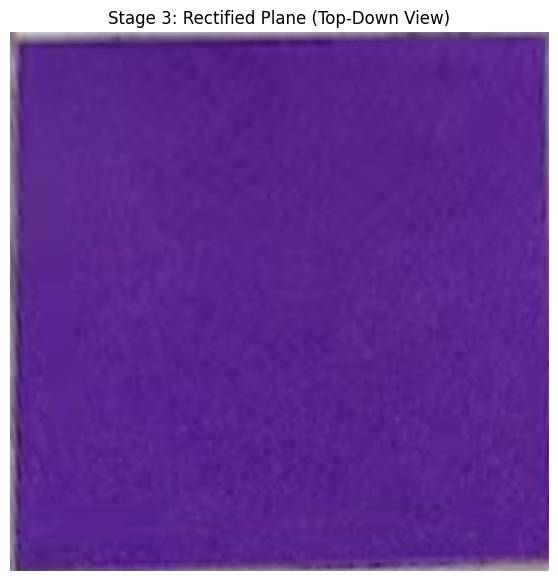

In [55]:
def H_from_correspondences(src_pts, dst_pts):
    srcn, Ts = normalize_points_2d(src_pts)
    dstn, Td = normalize_points_2d(dst_pts)
    A = []
    for (X,Y,_), (x,y,_) in zip(srcn, dstn):
        A.append([-X,-Y,-1, 0, 0, 0, x*X, x*Y, x])
        A.append([ 0, 0, 0,-X,-Y,-1, y*X, y*Y, y])
    A = np.asarray(A, dtype=np.float64)
    _, _, Vt = np.linalg.svd(A)
    Hn = Vt[-1].reshape(3,3)
    H = np.linalg.inv(Td) @ Hn @ Ts
    return H / H[2,2]

def normalize_points_2d(pts):
    pts = np.asarray(pts, dtype=np.float64)
    c = pts.mean(axis=0)
    d = np.sqrt(((pts - c)**2).sum(axis=1)).mean()
    s = np.sqrt(2.0) / (d + 1e-12)
    T = np.array([[s, 0, -s*c[0]],
                  [0, s, -s*c[1]],
                  [0, 0, 1]], dtype=np.float64)
    pts_h = np.c_[pts, np.ones(len(pts))]
    ptsn = (T @ pts_h.T).T
    return ptsn, T


def run_stage3_compute_H(ann_stage1_json, stage2_json, out_prefix="stage3to5"):
    with open(ann_stage1_json, "r", encoding="utf-8") as f:
        ann1 = json.load(f)
    quad = np.array(ann1.get("quad_ordered") or ann1.get("quad_raw"), dtype=np.float64)
    assert quad.shape == (4,2), "Quad must have 4 corners"
    unit_square = np.array([[0.0,0.0],[1.0,0.0],[1.0,1.0],[0.0,1.0]], dtype=np.float64)
    H = H_from_correspondences(unit_square, quad)
    reproj = []
    for XY, x_img in zip(unit_square, quad):
        Xh = np.array([XY[0], XY[1], 1.0])
        xp = (H @ Xh); xp = xp[:2] / xp[2]
        reproj.append(np.linalg.norm(xp - x_img))
    mean_err = float(np.mean(reproj))
    np.savez(f"{out_prefix}_stage3.npz", H=H, quad=quad, unit_square=unit_square, mean_err=mean_err)
    print("--- Stage 3 ---")
    print("Mean corner reprojection error:", round(mean_err, 3))
    return H, quad, unit_square

def run_stage3_warp_image(image_path, H, out_prefix="stage3to5", out_size=(500, 500)):
    img = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f"Image not found: {image_path}")
    W_out, H_out = out_size
    dst_pts = np.array([[0,0],[W_out-1,0],[W_out-1,H_out-1],[0,H_out-1]], dtype=np.float32)
    src_pts = np.asarray(H @ np.c_[np.array([[0,0],[1,0],[1,1],[0,1]]), np.ones(4)].T)
    src_pts = (src_pts[:2]/src_pts[2]).T.astype(np.float32)
    M = cv2.getPerspectiveTransform(src_pts, dst_pts)
    warped = cv2.warpPerspective(img, M, (W_out, H_out))
    out_path = f"{out_prefix}_stage3_rectified.png"
    cv2.imwrite(out_path, warped)
    print(f"Saved rectified image: {out_path}")
    plt.figure(figsize=(7,7))
    plt.imshow(cv2.cvtColor(warped, cv2.COLOR_BGR2RGB))
    plt.title("Stage 3: Rectified Plane (Top-Down View)")
    plt.axis('off'); plt.show()
    return warped

H, quad, unit_square = run_stage3_compute_H(ANN_STAGE1_JSON, STAGE2_JSON, OUT_PREFIX)
img_rectified = run_stage3_warp_image(IMAGE_PATH, H, OUT_PREFIX)

In [56]:
def draw_axes_overlay(img_bgr, K, R, t, origin_plane=(0.5,0.5), axis_len=0.5, thickness=3):
    base = img_bgr.copy()
    Ox, Oy = origin_plane
    P0 = np.array([[Ox, Oy, 0.0],
                   [Ox+axis_len, Oy, 0.0],
                   [Ox, Oy+axis_len, 0.0],
                   [Ox, Oy, axis_len]], dtype=np.float64)
    pts2d, _ = project_points(K, R, t, P0)
    p0, px, py, pz = [tuple(map(int, np.round(p))) for p in pts2d]
    cv2.line(base, p0, px, (0, 0, 255), thickness, cv2.LINE_AA)
    cv2.line(base, p0, py, (0, 255, 0), thickness, cv2.LINE_AA)
    cv2.line(base, p0, pz, (255, 0, 0), thickness, cv2.LINE_AA)
    return base


# Runs Stage 4: recover R,t and draw axes
def run_stage4_pose_axes(image_path, stage2_json, H, out_prefix="stage3to5"):
    img = cv2.imread(image_path, cv2.IMREAD_COLOR)
    with open(stage2_json, "r", encoding="utf-8") as f:
        ann2 = json.load(f)
    K = np.array(ann2["K"], dtype=np.float64)
    H_tilde = np.linalg.inv(K) @ H
    h1, h2, h3 = H_tilde[:,0], H_tilde[:,1], H_tilde[:,2]
    lam = 0.5 * (np.linalg.norm(h1) + np.linalg.norm(h2))
    if lam < 0: lam = -lam
    r1 = h1 / lam; r2 = h2 / lam; r3 = np.cross(r1, r2)
    R_hat = np.column_stack([r1, r2, r3])
    U, _, Vt = np.linalg.svd(R_hat)
    R = U @ Vt
    if np.linalg.det(R) < 0:
        U[:,-1] *= -1; R = U @ Vt
    t = h3 / lam
    test_pts = np.array([[0.5,0.5,0.0],[0.2,0.2,0.0],[0.8,0.2,0.0],[0.5,0.8,0.0]], dtype=np.float64)
    _, Xc = project_points(K, R, t, test_pts)
    if np.mean(Xc[:,2]) < 0:
        R[:,2] *= -1; t *= -1
    overlay_axes = draw_axes_overlay(img, K, R, t, origin_plane=(0.5,0.5), axis_len=0.9, thickness=4)
    plt.figure(figsize=(10,6))
    plt.imshow(cv2.cvtColor(overlay_axes, cv2.COLOR_BGR2RGB))
    plt.title("Stage 4: Camera Axes (X=Red, Y=Green, Z=Blue)")
    plt.axis('off'); plt.show()
    cv2.imwrite(f"{out_prefix}_stage4_axes.png", overlay_axes)
    np.savez(f"{out_prefix}_stage4.npz", R=R, t=t, K=K, H=H)
    return R, t, K, overlay_axes

R, t, K, overlay_axes = run_stage4_pose_axes(IMAGE_PATH, STAGE2_JSON, H, OUT_PREFIX)


LinAlgError: 0-dimensional array given. Array must be at least two-dimensional

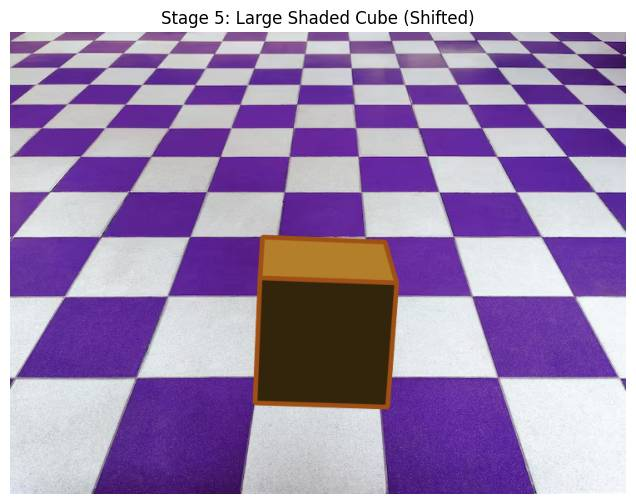

--- Face normals and brightness ---
Face 1 (0, 1, 5, 4) normal=[-0.0281 -0.3171  0.948 ] brightness=0.7076
Face 2 (4, 5, 6, 7) normal=[-0.0492  0.9476  0.3155] brightness=0.2
Face 3 (1, 2, 6, 5) normal=[0.9984 0.0377 0.0423] brightness=0.2
Face 4 (3, 0, 4, 7) normal=[-0.9984 -0.0377 -0.0423] brightness=0.2
Face 5 (0, 3, 2, 1) normal=[ 0.0492 -0.9476 -0.3155] brightness=0.7065
Face 6 (2, 3, 7, 6) normal=[ 0.0281  0.3171 -0.948 ] brightness=0.2


In [33]:
# Computes unit face normal in camera space from three vertices
def face_normal_cam(Xc, i0, i1, i2):
    v0, v1, v2 = Xc[i0], Xc[i1], Xc[i2]
    n = np.cross(v1 - v0, v2 - v0)
    d = np.linalg.norm(n) + 1e-12
    return n / d

def lambert_brightness(n_hat, l_hat, ambient=0.2):
    return float(max(ambient, float(np.dot(n_hat, -l_hat))))

# Runs Stage 5: project, shade, and render a **single large cube** with **adjustable offset**
def run_stage5_cube_shaded(image_path, K, R, t, out_prefix="stage3to5",
                           margin=0.03, size=0.94, 
                           offset_x=0.0, offset_y=0.0, offset_z=0.0,
                           light_dir=(-0.5, -0.5, -1.0), ambient=0.2):
    img = cv2.imread(image_path, cv2.IMREAD_COLOR)
    base_min = margin; base_max = margin + size
    base = np.array([[base_min, base_min, 0.0],
                     [base_max, base_min, 0.0],
                     [base_max, base_max, 0.0],
                     [base_min, base_max, 0.0]], dtype=np.float64)
    top = base.copy(); top[:,2] = size
    V = np.vstack([base, top])
    
    # Apply user-defined offset (shift in plane coordinates)
    offset = np.array([offset_x, offset_y, offset_z])
    V += offset
    
    edges = [(0,1),(1,2),(2,3),(3,0),(4,5),(5,6),(6,7),(7,4),(0,4),(1,5),(2,6),(3,7)]
    faces = [(0,3,2,1),(4,5,6,7),(0,1,5,4),(1,2,6,5),(2,3,7,6),(3,0,4,7)]
    
    # Project cube vertices
    pts2d, Xc = project_points(K, R, t, V)
    
    # --- Wireframe ---
    wire = img.copy()
    for (i,j) in edges:
        p1 = tuple(map(int, np.round(pts2d[i])))
        p2 = tuple(map(int, np.round(pts2d[j])))
        cv2.line(wire, p1, p2, (255,0,0), 3, cv2.LINE_AA)
    cv2.imwrite(f"{out_prefix}_stage5_wire.png", wire)
    
    # --- Shading ---
    l_hat = np.array(light_dir, dtype=np.float64)
    l_hat = l_hat / (np.linalg.norm(l_hat) + 1e-12)
    face_depths = []
    for f in faces:
        z_mean = float(np.mean(Xc[list(f), 2]))
        n_hat = face_normal_cam(Xc, f[0], f[1], f[2])
        b = lambert_brightness(n_hat, l_hat, ambient=ambient)
        face_depths.append((z_mean, f, b, n_hat))
    face_depths.sort(reverse=True)  # back-to-front
    
    shaded = img.copy()
    base_color = np.array([60, 180, 255], dtype=np.float64)
    face_stats = []
    for z_mean, f, b, n_hat in face_depths:
        poly = np.array([pts2d[i] for i in f], dtype=np.int32).reshape(-1,1,2)
        col = np.clip(base_color * b, 0, 255).astype(np.uint8)
        cv2.fillPoly(shaded, [poly], color=tuple(int(x) for x in col))
        cv2.polylines(shaded, [poly], isClosed=True, color=(20, 80, 160), thickness=3, lineType=cv2.LINE_AA)
        face_stats.append({
            "face": tuple(f),
            "normal": [float(n_hat[0]), float(n_hat[1]), float(n_hat[2])],
            "brightness": float(b)
        })
    
    # Save and display
    plt.figure(figsize=(10,6))
    plt.imshow(cv2.cvtColor(shaded, cv2.COLOR_BGR2RGB))
    plt.title("Stage 5: Large Shaded Cube (Shifted)"); plt.axis('off'); plt.show()
    cv2.imwrite(f"{out_prefix}_stage5_shaded.png", shaded)
    
    print("--- Face normals and brightness ---")
    for i, s in enumerate(face_stats):
        print(f"Face {i+1} {s['face']} normal={np.round(s['normal'],4)} brightness={round(s['brightness'],4)}")
    
    return wire, shaded, face_stats

# Call: large cube, shifted **down and left** (negative x = left, negative y = down in plane)
wire, shaded, face_stats = run_stage5_cube_shaded(
    IMAGE_PATH, K, R, t, OUT_PREFIX,
    margin=0.03, size=0.94,
    offset_x=-0.1,   # shift left
    offset_y=-1.3,   # shift down
    offset_z=0.0,    # no height change
    light_dir=(0.0, 1.0, -0.5), ambient=0.2
)